# 📈 Financial Analytics: Fatos Estilizados e Modelos de Volatilidade

**Autores:** Paloma Vaissman Uribe & Julio Trecenti  
**Instituição:** Insper, PADS | **Ano:** 2026

<a href="https://colab.research.google.com/github/padsInsper/202634-fa/blob/main/complementar/aula04-volatilidade-notebook.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

***

Notebook da **Aula 4**: execute as células em ordem.


### ⚙️ Instalação

In [69]:
import subprocess, sys
for pkg in ['yfinance', 'arch', 'statsmodels', 'scipy']:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])
print("✅ Pacotes instalados!")


✅ Pacotes instalados!


### Setup

In [70]:
import warnings, logging
warnings.filterwarnings('ignore')
logging.getLogger('arch').setLevel(logging.ERROR)

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from arch import arch_model

plt.style.use('default')
plt.rcParams.update({
    'figure.facecolor':'#FFFFFF','axes.facecolor':'#F9F9F9',
    'axes.edgecolor':'#BBBBBB','axes.labelcolor':'#1C1C1C',
    'xtick.color':'#444444','ytick.color':'#444444',
    'text.color':'#1C1C1C','grid.color':'#333',
    'grid.linestyle':'--','grid.alpha':0.5,'figure.dpi':110,
})
RED,BLUE,GREEN,GRAY,YELLOW = '#E4002B','#4a9eff','#2ecc71','#aaaaaa','#ffaa00'

data   = yf.download('PETR4.SA', start='2007-01-01', auto_adjust=True, progress=False)
prices = data['Close'].squeeze()
ret    = np.log(prices / prices.shift(1)).dropna()
print(f"✅ PETR4.SA carregada: {len(ret)} retornos ({ret.index[0].date()} → {ret.index[-1].date()})")


✅ PETR4.SA carregada: 4933 retornos (2007-01-03 → 2026-11-16)


***
## 🔴 Parte 1: Fatos Estilizados

### 1 · Preços

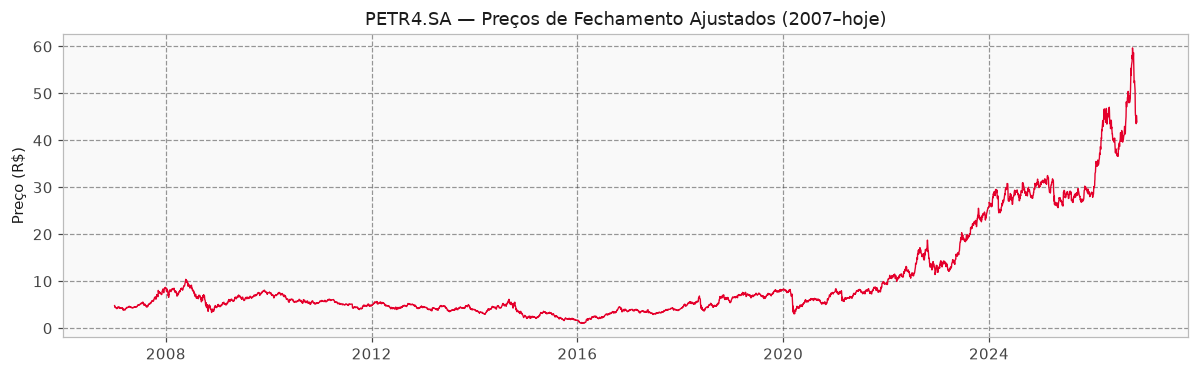

In [71]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(prices.index, prices.values, color=RED, lw=0.9)
ax.set_title('PETR4.SA: Preços de Fechamento Ajustados (2007-hoje)')
ax.set_ylabel('Preço (R$)'); ax.grid(True)
plt.tight_layout(); plt.show()


### 2 · Carregando Dados com `yfinance`

In [72]:
import yfinance as yf
import pandas as pd
import numpy as np

# Baixar dados reais da PETR4.SA desde 2007
data = yf.download('PETR4.SA',
                   start='2007-01-01',
                   auto_adjust=True,
                   progress=False)

prices = data['Close'].squeeze()
print(prices.tail())


Date
2026-11-10    44.950001
2026-11-11    43.549999
2026-11-12    44.700001
2026-11-13    45.299999
2026-11-16    43.900002
Name: PETR4.SA, dtype: float64


In [73]:
data

Price,Close,High,Low,Open,Volume
Ticker,PETR4.SA,PETR4.SA,PETR4.SA,PETR4.SA,PETR4.SA
Date,,,,,
2007-01-02,4.819327,4.831778,4.765694,4.788680,10244800
2007-01-03,4.672793,4.826988,4.598089,4.804003,19898600
2007-01-04,4.568400,4.668963,4.539668,4.645019,21060200
2007-01-05,4.429529,4.596175,4.319389,4.520514,24864000
2007-01-08,4.481246,4.514767,4.386430,4.453472,19440200
...,...,...,...,...,...
2026-11-10,44.950001,45.689999,44.500000,45.080002,54950000
2026-11-11,43.549999,44.520000,43.299999,44.000000,65089100


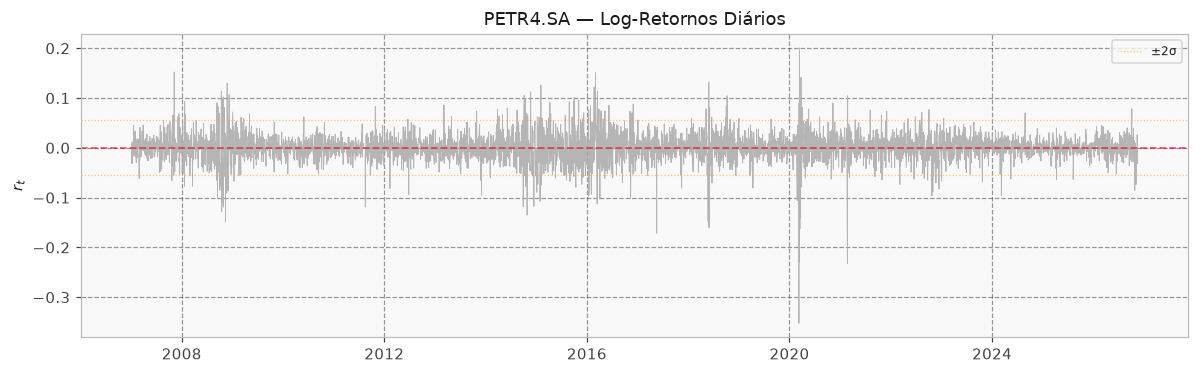

In [74]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(ret.index, ret.values, color=GRAY, lw=0.6, alpha=0.85)
ax.axhline(0, color=RED, lw=1.2, ls='--', alpha=0.6)
s = ret.std()
ax.axhline( 2*s, color=YELLOW, lw=0.8, ls=':', alpha=0.6, label='±2σ')
ax.axhline(-2*s, color=YELLOW, lw=0.8, ls=':', alpha=0.6)
ax.set_title('PETR4.SA: Log-Retornos Diários')
ax.set_ylabel('$r_t$'); ax.legend(fontsize=8); ax.grid(True)
plt.tight_layout(); plt.show()


### 3 · Fato 1: Não Normalidade

In [75]:
from scipy import stats

# Estatísticas descritivas
print(f"Assimetria:  {ret.skew():.4f}  (Normal: 0)")
print(f"Curtose:     {ret.kurtosis():.4f}  (Normal: 0)")

# Shapiro-Wilk exige n ≤ 5000, amostra com semente fixa
n_amostra = min(5000, len(ret))
stat, pval = stats.shapiro(ret.sample(n_amostra, random_state=42))
print(f"Shapiro-Wilk: W={stat:.4f}  p-value={pval:.2e}")


Assimetria:  -0.7414  (Normal: 0)
Curtose:     11.3912  (Normal: 0)
Shapiro-Wilk: W=0.9173  p-value=7.85e-46


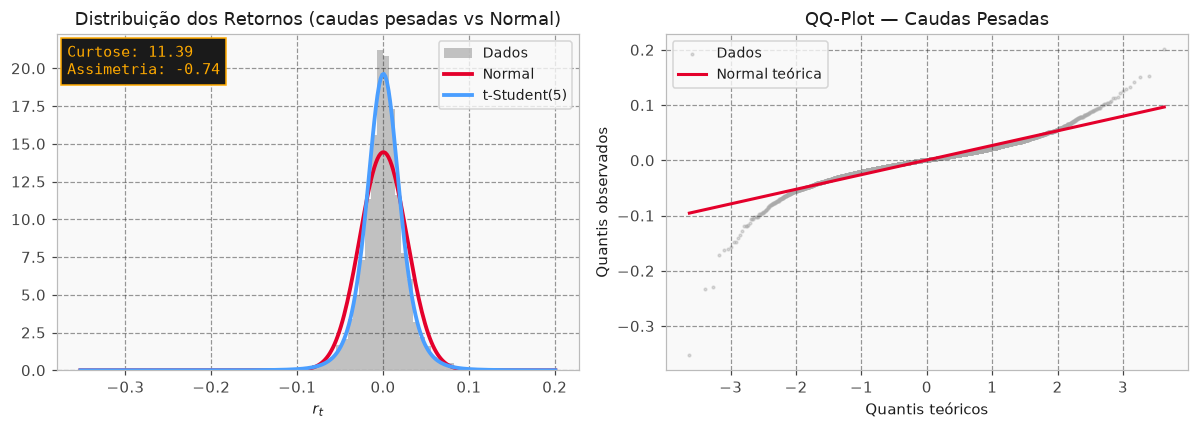

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x_range = np.linspace(ret.min(), ret.max(), 300)
mu_r, std_r = ret.mean(), ret.std()
axes[0].hist(ret, bins=80, color=GRAY, alpha=0.7, density=True, label='Dados')
axes[0].plot(x_range, stats.norm.pdf(x_range, mu_r, std_r), color=RED, lw=2.5, label='Normal')
axes[0].plot(x_range, stats.t.pdf(x_range, df=5, loc=mu_r, scale=std_r*0.7),
             color=BLUE, lw=2.5, label='t-Student(5)')
axes[0].set_title('Distribuição dos Retornos (caudas pesadas vs Normal)')
axes[0].set_xlabel('$r_t$'); axes[0].legend(fontsize=9); axes[0].grid(True)
axes[0].text(0.02, 0.97, f'Curtose: {ret.kurtosis():.2f}\nAssimetria: {ret.skew():.2f}',
    transform=axes[0].transAxes, fontsize=9.5, va='top', color=YELLOW,
    fontfamily='monospace', bbox=dict(facecolor='#1a1a1a', edgecolor=YELLOW, lw=1, pad=4))
(osm, osr), (slope, intercept, _) = stats.probplot(ret, dist='norm')
axes[1].scatter(osm, osr, color=GRAY, s=3, alpha=0.4, label='Dados')
line_x = np.array([osm[0], osm[-1]])
axes[1].plot(line_x, slope*line_x+intercept, color=RED, lw=2, label='Normal teórica')
axes[1].set_title('QQ-Plot: Caudas Pesadas')
axes[1].set_xlabel('Quantis teóricos'); axes[1].set_ylabel('Quantis observados')
axes[1].legend(fontsize=9); axes[1].grid(True)
plt.tight_layout(); plt.show()


### 3 · Fatos 2 e 3: Estacionaridade e Clusters

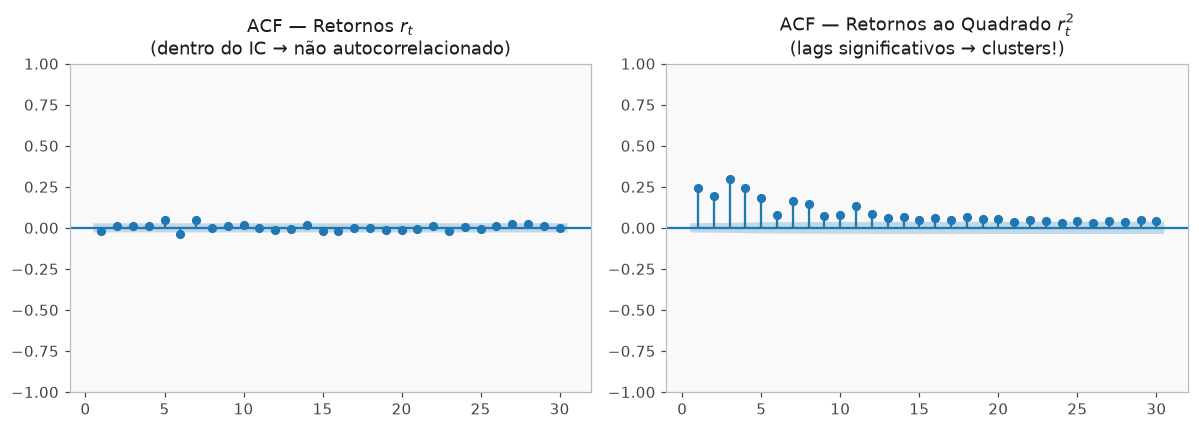

In [77]:
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Fato 2: ACF de r_t, quase sem autocorrelação
plot_acf(ret, ax=axes[0], lags=30, zero=False,
         title='ACF: Retornos $r_t$\n(dentro do IC → não autocorrelacionado)')

# Fato 3: ACF de r_t², memória na volatilidade!
plot_acf(ret**2, ax=axes[1], lags=30, zero=False,
         title='ACF: Retornos ao Quadrado $r_t^2$\n(lags significativos → clusters!)')

plt.tight_layout()
plt.show()


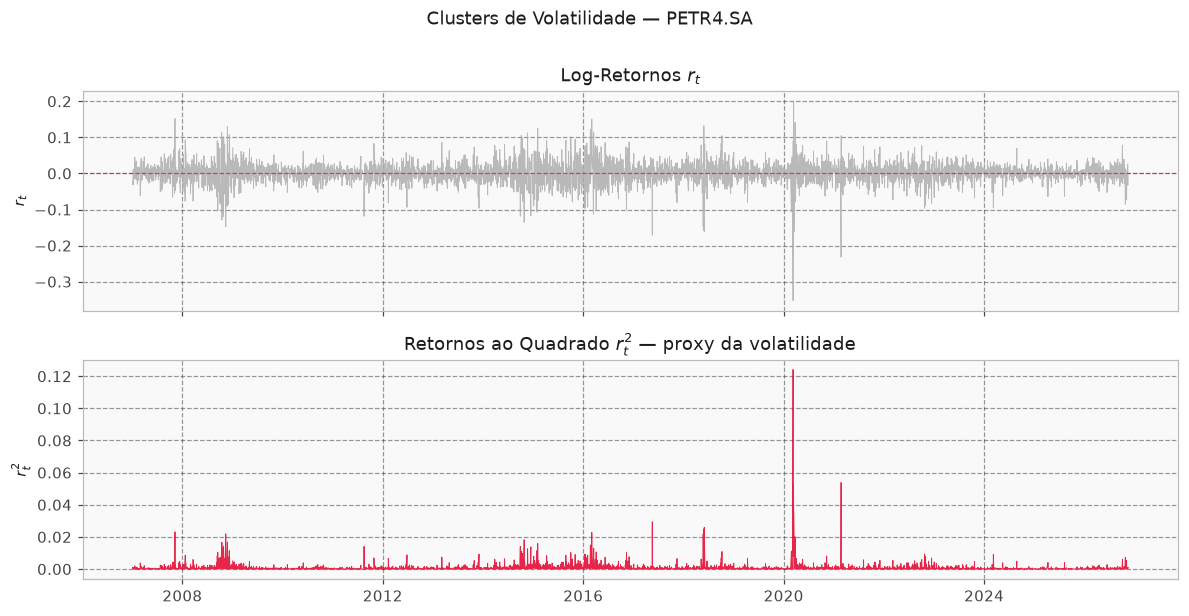

In [78]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axes[0].plot(ret.index, ret.values, color=GRAY, lw=0.6, alpha=0.8)
axes[0].axhline(0, color=RED, lw=0.8, ls='--', alpha=0.6)
axes[0].set_title('Log-Retornos $r_t$'); axes[0].set_ylabel('$r_t$'); axes[0].grid(True)
axes[1].plot(ret.index, ret.values**2, color=RED, lw=0.6, alpha=0.85)
axes[1].set_title('Retornos ao Quadrado $r_t^2$: proxy da volatilidade')
axes[1].set_ylabel('$r_t^2$'); axes[1].grid(True)
fig.suptitle('Clusters de Volatilidade: PETR4.SA', fontsize=12, y=1.01)
plt.tight_layout(); plt.show()


### 4 · Testando Efeitos ARCH

In [79]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Ljung-Box nos retornos ao quadrado
lb = acorr_ljungbox(ret**2, lags=[12], return_df=True)
print(lb)
# p-value << 0.05 → rejeita H₀ → há efeitos ARCH


        lb_stat  lb_pvalue
12  1802.281688        0.0


In [80]:
from arch import arch_model

# Teste LM via arch
am = arch_model(ret, vol='ARCH', p=12)
res = am.fit(disp='off')
print(res.arch_lm_test(lags=12))


ARCH-LM Test
H0: Residuals are homoskedastic.
ARCH-LM Test
H1: Residuals are conditionally heteroskedastic.
Statistic: 798.6527
P-value: 0.0000
Distributed: <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x117e44b90>


***
## 🔴 Parte 2: Modelos de Volatilidade

### 6 · Ajustando ARCH(12) com Python

In [81]:
from arch import arch_model

# ARCH(12) com distribuição Normal
m1 = arch_model(ret, mean='Constant', vol='ARCH', p=12, dist='normal')
res1 = m1.fit(disp='off')
print(res1.summary())


                      Constant Mean - ARCH Model Results                      
Dep. Variable:               PETR4.SA   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                       ARCH   Log-Likelihood:                11385.7
Distribution:                  Normal   AIC:                          -22743.5
Method:            Maximum Likelihood   BIC:                          -22652.4
                                        No. Observations:                 4933
Date:                Mon, Nov 16 2026   Df Residuals:                     4932
Time:                        17:46:24   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu         9.3107e-04  3.225e-04      2.887  3.887e-03 [2.

In [82]:
# ARCH(12) com distribuição t-Student (caudas mais pesadas)
m2 = arch_model(ret, mean='Constant', vol='ARCH', p=12, dist='t')
res2 = m2.fit(disp='off')

# Comparar AIC/BIC
print(f"ARCH(12) Normal | AIC: {res1.aic:.1f}  BIC: {res1.bic:.1f}")
print(f"ARCH(12) t-Student | AIC: {res2.aic:.1f}  BIC: {res2.bic:.1f}")


ARCH(12) Normal | AIC: -22743.5  BIC: -22652.4
ARCH(12) t-Student | AIC: 15084.6  BIC: 15182.2


/var/folders/x8/s2yknq512_x7xmn7rrcl2kzw0000gn/T/ipykernel_30291/2476515880.py:3: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  res2 = m2.fit(disp='off')


In [83]:
ret

Date
2007-01-03   -0.030877
2007-01-04   -0.022594
2007-01-05   -0.030870
2007-01-08    0.011608
2007-01-09   -0.031039
                ...   
2026-11-10   -0.005325
2026-11-11   -0.031641
2026-11-12    0.026064
2026-11-13    0.013333
2026-11-16   -0.031165
Name: PETR4.SA, Length: 4933, dtype: float64

### 7 · Ajustando GARCH(1,1)

In [208]:
# GARCH(1,1) com distribuição Normal
m3 = arch_model(ret, mean='Constant', vol='GARCH', p=1, q=1, dist='normal')
res3 = m3.fit(disp='off')

# GARCH(1,1) com distribuição t-Student (preferível)
m4 = arch_model(ret, mean='Constant', vol='GARCH', p=1, q=1, dist='t')
res4 = m4.fit(disp='off')

print(res4.params)


mu            0.000197
omega         0.006474
alpha[1]      0.995856
beta[1]       0.005703
nu          322.664164
Name: params, dtype: float64


/var/folders/x8/s2yknq512_x7xmn7rrcl2kzw0000gn/T/ipykernel_30291/1371308973.py:7: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  res4 = m4.fit(disp='off')


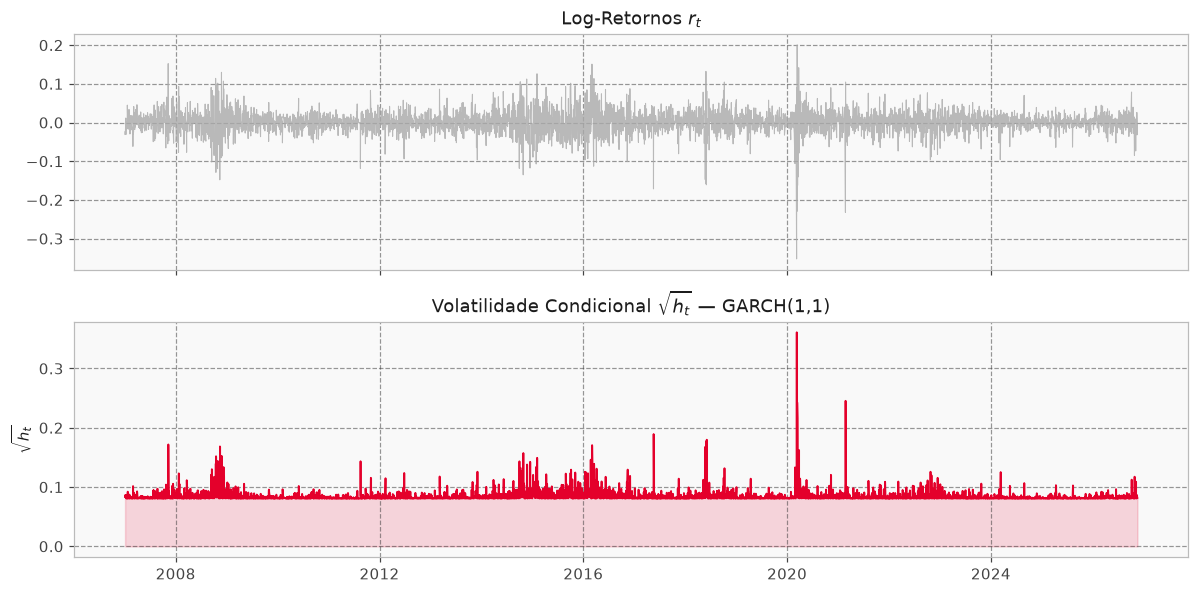

In [221]:
# Extrair volatilidade condicional estimada
vol_estimada = res4.conditional_volatility

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axes[0].plot(ret.index, ret.values, color=GRAY, lw=0.7, alpha=0.8)
axes[0].set_title('Log-Retornos $r_t$'); axes[0].grid(True)

axes[1].plot(vol_estimada.index, vol_estimada.values, color=RED, lw=1.2)
axes[1].fill_between(vol_estimada.index, 0, vol_estimada.values,
                     color=RED, alpha=0.15)
axes[1].set_title('Volatilidade Condicional $\sqrt{h_t}$: GARCH(1,1)')
axes[1].set_ylabel('$\sqrt{h_t}$'); axes[1].grid(True)
plt.tight_layout()
plt.show()


In [222]:
print(f"{'Modelo':30s}  {'AIC':>10}  {'BIC':>10}  {'Parâmetros':>10}")
print('-'*66)
for nome, res in [('ARCH(12) Normal', res1), ('ARCH(12) t-Student', res2),
                   ('GARCH(1,1) Normal', res3), ('GARCH(1,1) t-Student', res4)]:
    print(f"{nome:30s}  {res.aic:10.1f}  {res.bic:10.1f}  {len(res.params):10d}")


Modelo                                 AIC         BIC  Parâmetros
------------------------------------------------------------------
ARCH(12) Normal                   -22743.5    -22652.4          14
ARCH(12) t-Student                 15084.6     15182.2          15
GARCH(1,1) Normal                 -22798.2    -22772.2           4
GARCH(1,1) t-Student              -14861.9    -14829.4           5


### 8 · Diagnóstico dos Resíduos

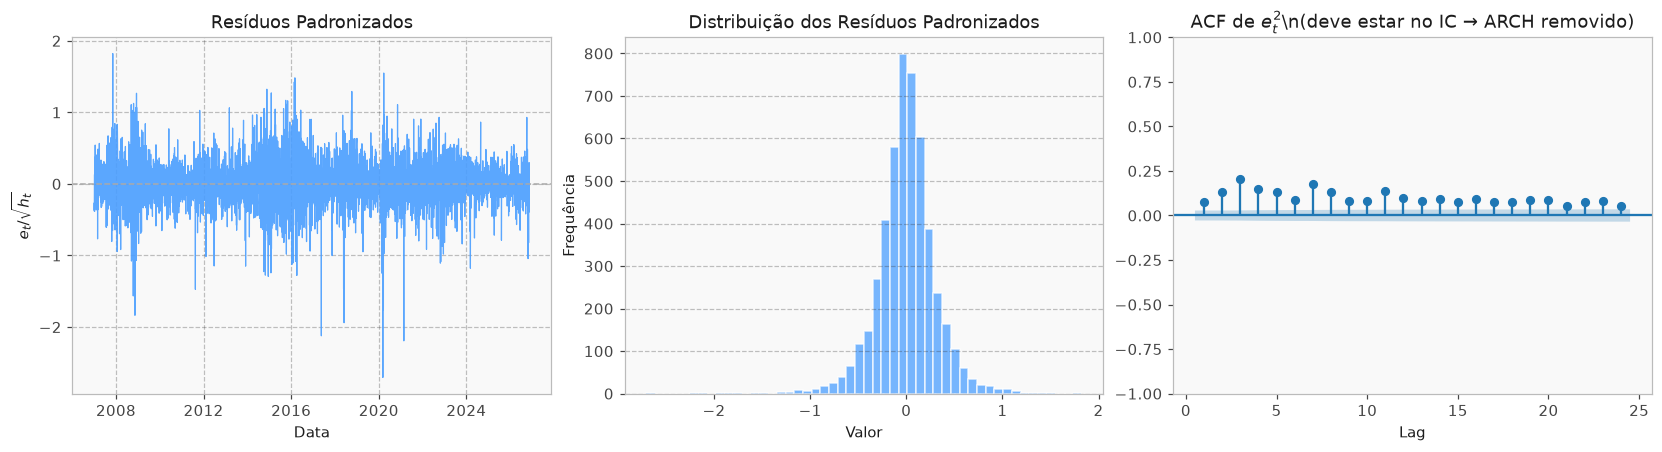

Ljung-Box (e_t^2): p-value = 0.0000
⚠️ Ainda há evidência de dependência na variância; o modelo pode não capturar tudo.


In [223]:
# Diagnóstico dos resíduos do GARCH(1,1) t-Student
# Este bloco corrige e garante que o gráfico apareça no Jupyter

# Garante que a série e o modelo existam
if 'res4' not in globals():
    raise NameError("O modelo 'res4' não foi encontrado. Ajuste o GARCH(1,1) antes de rodar este diagnóstico.")

# Resíduos padronizados
resid_std = pd.Series(res4.std_resid, index=ret.index).dropna()
resid_sq = resid_std**2

# Limpa figuras antigas para evitar "plote preso" em memória
plt.close('all')

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

# 1) Série de resíduos padronizados
axes[0].plot(resid_std.index, resid_std.values, color=BLUE, lw=0.8, alpha=0.9)
axes[0].axhline(0, color=GRAY, ls='--', lw=1)
axes[0].set_title('Resíduos Padronizados')
axes[0].set_xlabel('Data')
axes[0].set_ylabel('$e_t / \\sqrt{h_t}$')
axes[0].grid(True, alpha=0.3)

# 2) Histograma
axes[1].hist(resid_std.values, bins=50, color=BLUE, alpha=0.75, edgecolor='white')
axes[1].set_title('Distribuição dos Resíduos Padronizados')
axes[1].set_xlabel('Valor')
axes[1].set_ylabel('Frequência')
axes[1].grid(True, axis='y', alpha=0.3)

# 3) ACF dos resíduos ao quadrado
plot_acf(resid_sq, ax=axes[2], lags=24, zero=False,
         title='ACF de $e_t^2$\\n(deve estar no IC → ARCH removido)')
axes[2].set_xlabel('Lag')

plt.show()

# Teste de Ljung-Box nos resíduos ao quadrado
lb = acorr_ljungbox(resid_sq, lags=[20], return_df=True)
p_value = float(lb['lb_pvalue'].iloc[0])

print(f"Ljung-Box (e_t^2): p-value = {p_value:.4f}")
if p_value > 0.05:
    print("✅ Não há evidência de efeitos ARCH remanescentes; o modelo ficou bem ajustado.")
else:
    print("⚠️ Ainda há evidência de dependência na variância; o modelo pode não capturar tudo.")

### 9 · Volatilidade por Janelas Móveis

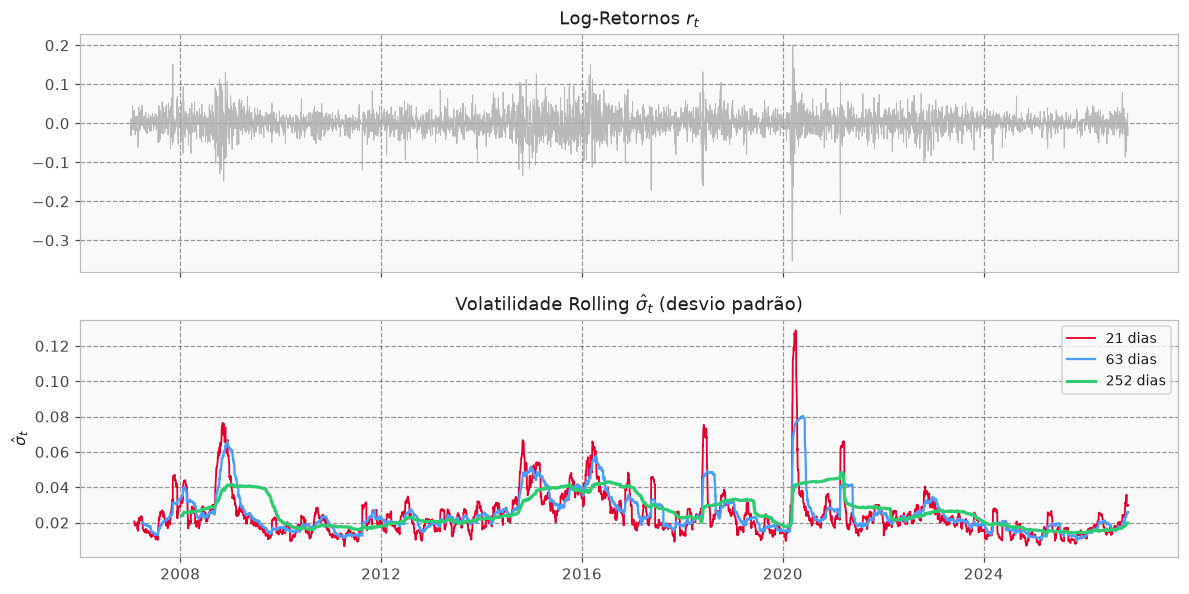

In [224]:
# Desvio padrão rolling: janela de 21 dias (~1 mês) e 63 dias (~1 trimestre)
vol_21  = ret.rolling(window=21).std()    # janela curta, mais reativa
vol_63  = ret.rolling(window=63).std()    # janela longa, mais suave
vol_252 = ret.rolling(window=252).std()   # janela anual, tendência

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)

axes[0].plot(ret.index, ret.values, color=GRAY, lw=0.6, alpha=0.8)
axes[0].set_title('Log-Retornos $r_t$'); axes[0].grid(True)

axes[1].plot(vol_21.index,  vol_21,  color=RED,   lw=1.2, label='21 dias')
axes[1].plot(vol_63.index,  vol_63,  color=BLUE,  lw=1.5, label='63 dias')
axes[1].plot(vol_252.index, vol_252, color=GREEN, lw=2.0, label='252 dias')
axes[1].set_title('Volatilidade Rolling $\hat{\sigma}_t$ (desvio padrão)')
axes[1].set_ylabel('$\hat{\sigma}_t$'); axes[1].legend(fontsize=9)
axes[1].grid(True)
plt.tight_layout()
plt.show()


Convergência: True
mu          0.087515
omega       0.073151
alpha[1]    0.073042
beta[1]     0.920067
nu          5.195144
Name: params, dtype: float64


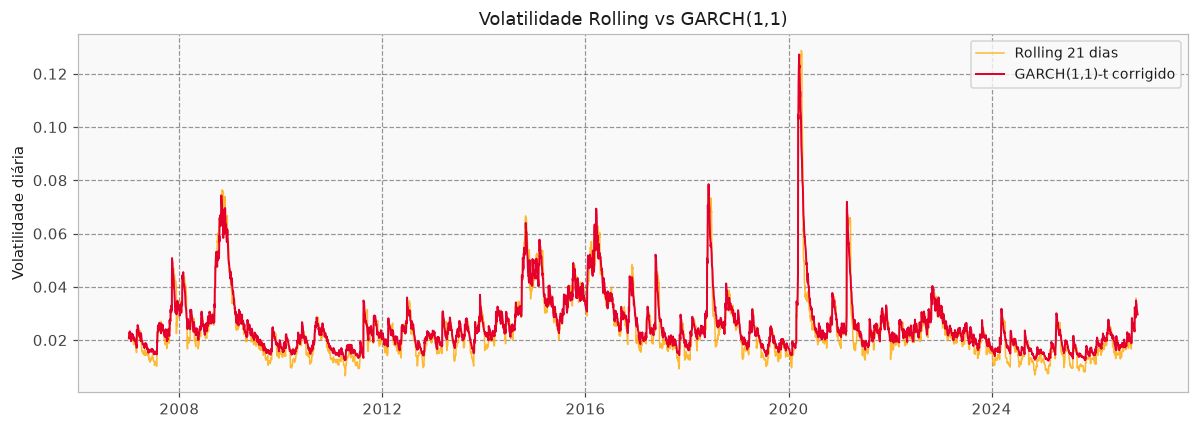

In [241]:
# Ajusta GARCH-t em pontos percentuais para melhorar a estabilidade numérica
m4 = arch_model(
    ret * 100, mean='Constant', vol='GARCH', p=1, q=1, dist='t'
).fit(disp='off')

vol_garch = m4.conditional_volatility / 100

print(f"Convergência: {m4.convergence_flag == 0}")
print(m4.params)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(vol_roll_21.index, vol_roll_21, color=YELLOW, lw=1.0,
        alpha=0.8, label='Rolling 21 dias')
ax.plot(vol_garch.index, vol_garch, color=RED, lw=1.3,
        label='GARCH(1,1)-t corrigido')
ax.set_title('Volatilidade Rolling vs GARCH(1,1)')
ax.set_ylabel('Volatilidade diária')
ax.legend(fontsize=9)
ax.grid(True)
plt.tight_layout()
plt.show()

### 10 · Modelo IGARCH

In [242]:
from arch.univariate import ConstantMean, EWMAVariance, Normal

# IGARCH ≡ EWMA/RiskMetrics: alpha + beta = 1 por construção
# EWMAVariance é o processo correto na lib arch
m5 = ConstantMean(ret)
m5.volatility = EWMAVariance(lam=0.94)   # lambda=0.94 (RiskMetrics padrão)
m5.distribution = Normal()
res5 = m5.fit(disp='off')
print(res5.params)
print(f"\nEWMA lam=0.94 → equivalente ao IGARCH: alpha+beta=1")


mu    0.000531
Name: params, dtype: float64

EWMA lam=0.94 → equivalente ao IGARCH: alpha+beta=1


### 10 · Modelo EGARCH: Efeito Alavancagem

In [243]:
m6 = arch_model(ret, mean='Constant', vol='EGARCH', p=1, q=1, dist='normal')
res6 = m6.fit(disp='off')
print(res6.params)
# gamma[1] > 0 → bad news tem maior impacto na volatilidade


mu          0.001293
omega      -0.187015
alpha[1]    0.160386
beta[1]     0.973489
Name: params, dtype: float64


### 10 · News Impact Curve: GARCH vs EGARCH

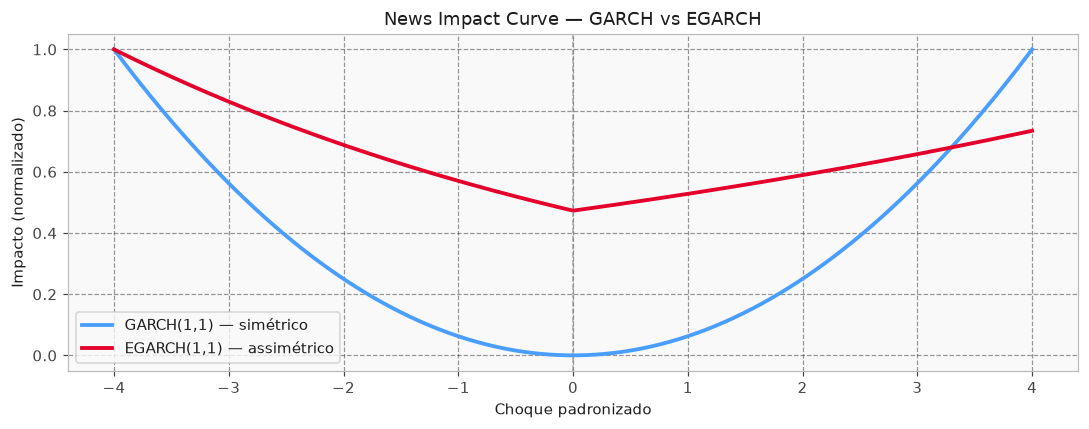

gamma[1] do EGARCH: -0.0386


In [249]:
# EGARCH(1,1) com assimetria
m6 = arch_model(ret, mean='Constant', vol='EGARCH',
                p=1, o=1, q=1, dist='normal')
res6 = m6.fit(disp='off')

xi = np.linspace(-4, 4, 300)

# News impact: componente simétrico + componente assimétrico
alpha_e = res6.params['alpha[1]']
gamma_e = res6.params['gamma[1]']

nic_garch = res4.params['omega'] + res4.params['alpha[1]'] * xi**2
nic_egarch = np.exp(
    alpha_e * (np.abs(xi) - np.sqrt(2 / np.pi)) + gamma_e * xi
)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(xi, nic_garch / nic_garch.max(),
        color=BLUE, lw=2.5, label='GARCH(1,1): simétrico')
ax.plot(xi, nic_egarch / nic_egarch.max(),
        color=RED, lw=2.5, label='EGARCH(1,1): assimétrico')
ax.axvline(0, color='#888', lw=1, ls='--', alpha=0.7)
ax.set_title('News Impact Curve: GARCH vs EGARCH')
ax.set_xlabel('Choque padronizado')
ax.set_ylabel('Impacto (normalizado)')
ax.legend(fontsize=10)
ax.grid(True)
plt.tight_layout()
plt.show()

print(f"gamma[1] do EGARCH: {gamma_e:.4f}")

### 10 · Modelo TGARCH (GJR-GARCH)

In [250]:
# TGARCH via arch (GJR-GARCH)
m7 = arch_model(ret, mean='Constant', vol='GARCH', p=1, o=1, q=1, dist='normal')
res7 = m7.fit(disp='off')
print(res7.params)
# gamma[1] > 0 → bad news adiciona impacto extra


mu          0.000448
omega       0.000015
alpha[1]    0.050000
gamma[1]    0.050000
beta[1]     0.905000
Name: params, dtype: float64


### 11 · SV: Estimação via Filtro de Kalman

In [257]:
# Transformação: log(r_t²) ≈ h_t + kappa_t
log_r2 = np.log(ret**2 + 1e-10)

phi_sv, sigma_sv, mu_sv = 0.97, 0.15, log_r2.mean()

h_filt = np.zeros(len(ret)); P_filt = np.zeros(len(ret))
h_pred = mu_sv
P_pred = sigma_sv**2 / (1 - phi_sv**2)
KAPPA  = -1.2704
V_obs  = np.pi**2 / 2

for t, y in enumerate(log_r2):
    K         = P_pred / (P_pred + V_obs)
    h_filt[t] = h_pred + K * (y - h_pred - KAPPA)
    P_filt[t] = (1 - K) * P_pred
    h_pred    = mu_sv + phi_sv * (h_filt[t] - mu_sv)
    P_pred    = phi_sv**2 * P_filt[t] + sigma_sv**2

vol_sv    = np.exp(h_filt / 2)
vol_sv_hi = np.exp((h_filt + 1.96 * np.sqrt(P_filt)) / 2)
vol_sv_lo = np.exp((h_filt - 1.96 * np.sqrt(P_filt)) / 2)

print(f"Vol SV | média: {vol_sv.mean():.4f}  máx: {vol_sv.max():.4f}")
print(f"Vol GARCH | média: {(vol_garch).mean():.4f}")


Vol SV | média: 0.0155  máx: 0.0394
Vol GARCH | média: 0.0256


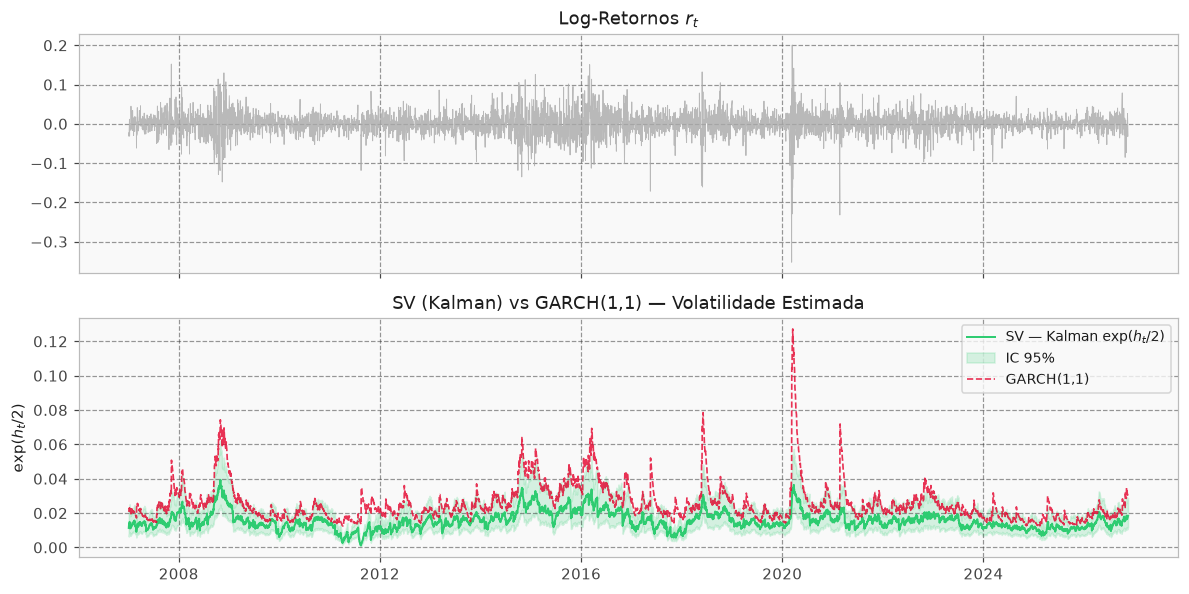

In [260]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axes[0].plot(ret.index, ret.values, color=GRAY, lw=0.6, alpha=0.8)
axes[0].set_title('Log-Retornos $r_t$'); axes[0].grid(True)
axes[1].plot(ret.index, vol_sv,    color=GREEN, lw=1.3, label='SV: Kalman $\exp(h_t/2)$')
axes[1].fill_between(ret.index, vol_sv_lo, vol_sv_hi, color=GREEN, alpha=0.18, label='IC 95%')
axes[1].plot(ret.index, vol_garch,
             color=RED, lw=1.1, ls='--', alpha=0.8, label='GARCH(1,1)')
axes[1].set_title('SV (Kalman) vs GARCH(1,1): Volatilidade Estimada')
axes[1].set_ylabel('$\exp(h_t/2)$'); axes[1].legend(fontsize=9); axes[1].grid(True)
plt.tight_layout(); plt.show()


***
## 🏋️ Exercício Proposto

1. Baixe dados de **VALE3.SA** ou **^BVSP** via `yfinance` (2007-hoje)
2. Calcule os log-retornos e verifique os **3 fatos estilizados**
3. Compare curtose e assimetria com os valores da PETR4.SA
4. Aplique os **testes Ljung-Box e LM**, há efeitos ARCH?
5. Ajuste **ARCH(12)** e **GARCH(1,1)** com Normal e t-Student
6. Compare via **AIC/BIC**, qual modelo vence?
7. Verifique o diagnóstico, os efeitos ARCH foram removidos?
8. **Bônus:** ajuste EGARCH(1,1), há efeito de alavancagem ($\gamma \neq 0$)?


In [261]:
TICKER = 'VALE3.SA'   # troque aqui: 'VALE3.SA' ou '^BVSP'

data_ex   = yf.download(TICKER, start='2007-01-01', auto_adjust=True, progress=False)
prices_ex = data_ex['Close'].squeeze()
ret_ex    = np.log(prices_ex / prices_ex.shift(1)).dropna()

print(f"Série: {TICKER}")
print(f"Período: {ret_ex.index[0].date()} → {ret_ex.index[-1].date()}")
print(f"Observações: {len(ret_ex)}")
print(f"Assimetria:  {ret_ex.skew():.4f}")
print(f"Curtose:     {ret_ex.kurtosis():.4f}")


Série: VALE3.SA
Período: 2007-01-03 → 2026-11-16
Observações: 4933
Assimetria:  -0.2222
Curtose:     7.5748


***
## 📖 Referências

- **Análise de Séries Temporais Financeiras**, Tsay (2010) · Caps. 3-4
- **arch: ARCH and GARCH Models** · [arch.readthedocs.io](https://arch.readthedocs.io/)
- **yfinance** · [pypi.org/project/yfinance](https://pypi.org/project/yfinance/)
- **Material do curso** · [padsinsper.github.io/202632-fa](https://padsinsper.github.io/202632-fa/)
